# Asimov Containment Closure Test

Same closure check as `Asimov_Studies.ipynb`, but for the containment-split (contained/exiting) simultaneous fit. Reads from the `Asimov_Containment` output directory produced by the fitter/toy-generator runs.

**Binning:** truth binning is the medulla-optimized *combined* dpT binning (`binning_true_dpT.txt`, 6 finite + 1 overflow = 7 bins, shared across all 4 samples). Reco binning is per-channel: contained samples use `binning_reco_dpT_contained.txt` (20 finite + 1 overflow = 21 rows), exiting samples use `binning_reco_dpT_exiting.txt` (10 finite + 1 overflow = 11 rows).

**`cov_bin_range` -- VERIFIED against the actual ROOT file (2026-08-26).** Two objects in the toyGen output use different bin counts for the same sample: `covarianceMatrix_TH2D` keeps the overflow row (so each sample's true block is 21 or 11 wide), but the category histograms under `toyGen/plots/histograms/.../MC_TH1D` silently drop the overflow row (20 or 10 bins). Confirmed directly via the TH2D axis labels: block boundaries in the full 64x64 matrix are at 0, 21, 32, 53, 64 (with-overflow widths), but each slice used for chi2 must stop one row short of its block boundary to match the category histograms: selection_contained (0,20), selection_exiting (21,31), sideband_contained (32,52), sideband_exiting (53,63). This matches the same overflow-excluding convention the original 2-sample notebook always used (its `cov_bin_range=(0,12)` on a 13-row file was never a coincidence).

In [1]:
try:
    from src.save_fig import save_fig
except ImportError:
    import sys, os
    sys.path.append(os.path.abspath('..'))
    from src.save_fig import save_fig

import sys
import os
sys.path.append(os.path.abspath(".."))
from src.plot_scatter import plot_scatter
from src.plot_manual_cross_section import overlay_manual_cross_section
from src.plot_fit_constraints import plot_fit_constraints
from src.plot_gundam_stacked import plot_gundam_stacked
from src.plot_GENIE_NUISANCE import overlay_genie_nuisance_xsec
from src.plot_matrices import plot_both_matrices

## Selection - Contained

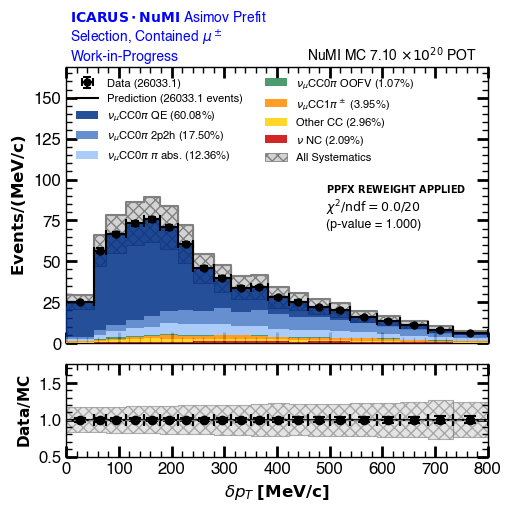

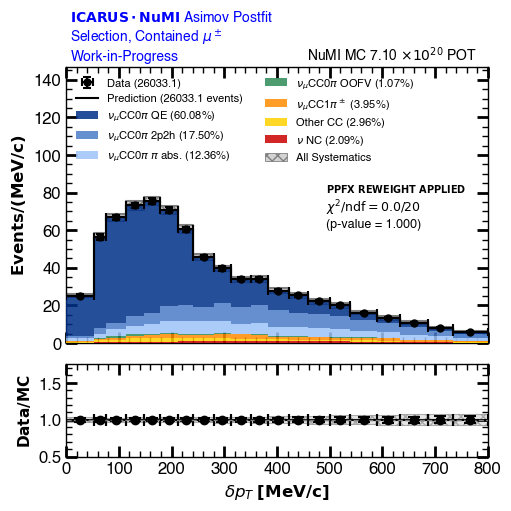

In [2]:
# Pre-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/Asimov_Containment/prefit_asimov_dpT_containment.root',
    fitterengine_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/Asimov_Containment/asimov_dpT_containment.root',
    sample_name='selection_reco_dpT_contained',
    variable_name='reco_dpT_lp',
    cov_bin_range=(0, 20),  # Block [0,21) includes the overflow row in the covariance matrix, but the category histograms drop it -- slice one short of the true block boundary. See markdown note.
    fit_type='pre-fit',
    xlabel=r'$\delta p_T$ $\mathbf{[MeV/c]}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Asimov Prefit' + '\n' + 'Selection, Contained $\mu^\pm$' + '\n' + 'Work-in-Progress',
    save_dir=r'../Plots/dpT/Asimov_Containment/Prefits', save_name='prefit_dpT_selection_contained',
    pot=r'NuMI MC 7.10 $\times 10^{20}$ POT',
)

# Post-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/Asimov_Containment/postfit_asimov_dpT_containment.root',
    fitterengine_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/Asimov_Containment/asimov_dpT_containment.root',
    sample_name='selection_reco_dpT_contained',
    variable_name='reco_dpT_lp',
    cov_bin_range=(0, 20),  # see note above
    fit_type='post-fit',
    xlabel=r'$\delta p_T$ $\mathbf{[MeV/c]}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Asimov Postfit' + '\n' + 'Selection, Contained $\mu^\pm$' + '\n' + 'Work-in-Progress',
    pot=r'NuMI MC 7.10 $\times 10^{20}$ POT',
    save_dir=r'../Plots/dpT/Asimov_Containment/Postfits', save_name='postfit_dpT_selection_contained'
)

## Selection - Exiting

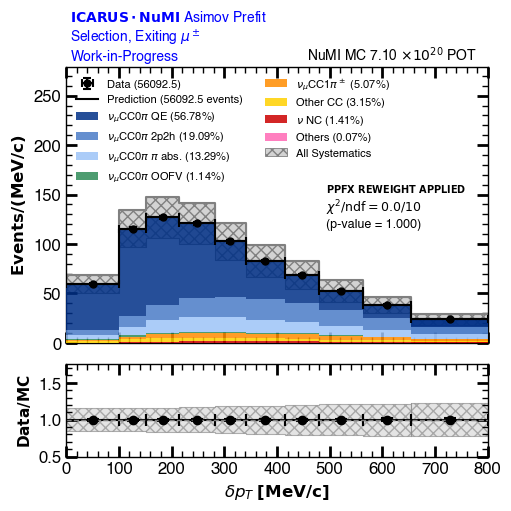

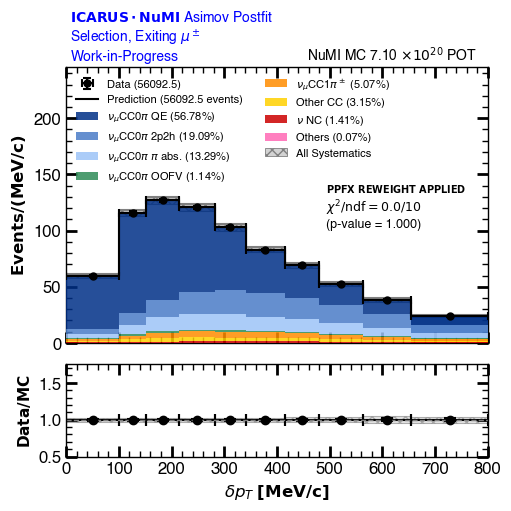

In [3]:
# Pre-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/Asimov_Containment/prefit_asimov_dpT_containment.root',
    fitterengine_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/Asimov_Containment/asimov_dpT_containment.root',
    sample_name='selection_reco_dpT_exiting',
    variable_name='reco_dpT_lp',
    cov_bin_range=(21, 31),  # True block [21,32) includes the overflow row; category histograms only have 10 bins. See markdown note.
    fit_type='pre-fit',
    xlabel=r'$\delta p_T$ $\mathbf{[MeV/c]}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Asimov Prefit' + '\n' + 'Selection, Exiting $\mu^\pm$' + '\n' + 'Work-in-Progress',
    save_dir=r'../Plots/dpT/Asimov_Containment/Prefits', save_name='prefit_dpT_selection_exiting',
    pot=r'NuMI MC 7.10 $\times 10^{20}$ POT',
)

# Post-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/Asimov_Containment/postfit_asimov_dpT_containment.root',
    fitterengine_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/Asimov_Containment/asimov_dpT_containment.root',
    sample_name='selection_reco_dpT_exiting',
    variable_name='reco_dpT_lp',
    cov_bin_range=(21, 31),  # see note above
    fit_type='post-fit',
    xlabel=r'$\delta p_T$ $\mathbf{[MeV/c]}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Asimov Postfit' + '\n' + 'Selection, Exiting $\mu^\pm$' + '\n' + 'Work-in-Progress',
    pot=r'NuMI MC 7.10 $\times 10^{20}$ POT',
    save_dir=r'../Plots/dpT/Asimov_Containment/Postfits', save_name='postfit_dpT_selection_exiting'
)

## Sideband - Contained

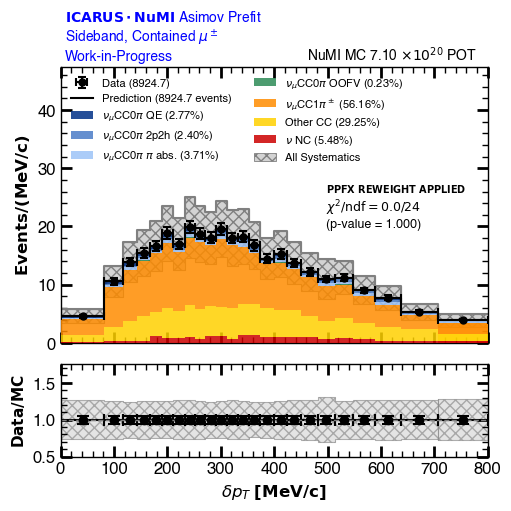

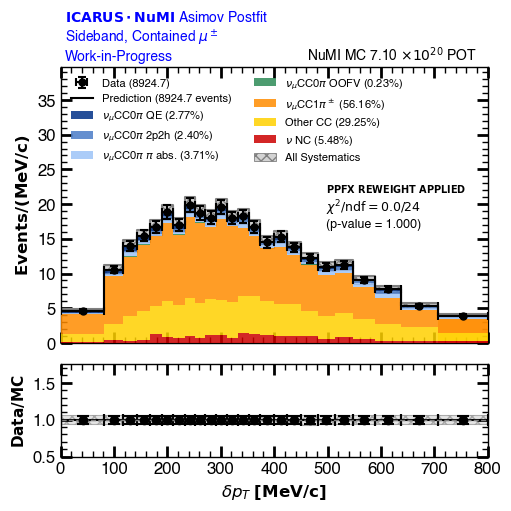

In [4]:
# Pre-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/Asimov_Containment/prefit_asimov_dpT_containment.root',
    fitterengine_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/Asimov_Containment/asimov_dpT_containment.root',
    sample_name='sideband_reco_dpT_contained',
    variable_name='reco_dpT_lp',
    cov_bin_range=(32, 56),  # True block [32,57) includes the overflow row; sideband now uses its own binning (binning_reco_dpT_sideband_contained.txt, 25 rows), not the selection's. Category histograms have 24 finite bins. See markdown note.
    fit_type='pre-fit',
    xlabel=r'$\delta p_T$ $\mathbf{[MeV/c]}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Asimov Prefit' + '\n' + 'Sideband, Contained $\mu^\pm$' + '\n' + 'Work-in-Progress',
    save_dir=r'../Plots/dpT/Asimov_Containment/Prefits', save_name='prefit_dpT_sideband_contained',
    pot=r'NuMI MC 7.10 $\times 10^{20}$ POT',
)

# Post-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/Asimov_Containment/postfit_asimov_dpT_containment.root',
    fitterengine_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/Asimov_Containment/asimov_dpT_containment.root',
    sample_name='sideband_reco_dpT_contained',
    variable_name='reco_dpT_lp',
    cov_bin_range=(32, 56),  # see note above
    fit_type='post-fit',
    xlabel=r'$\delta p_T$ $\mathbf{[MeV/c]}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Asimov Postfit' + '\n' + 'Sideband, Contained $\mu^\pm$' + '\n' + 'Work-in-Progress',
    pot=r'NuMI MC 7.10 $\times 10^{20}$ POT',
    save_dir=r'../Plots/dpT/Asimov_Containment/Postfits', save_name='postfit_dpT_sideband_contained'
)

## Sideband - Exiting

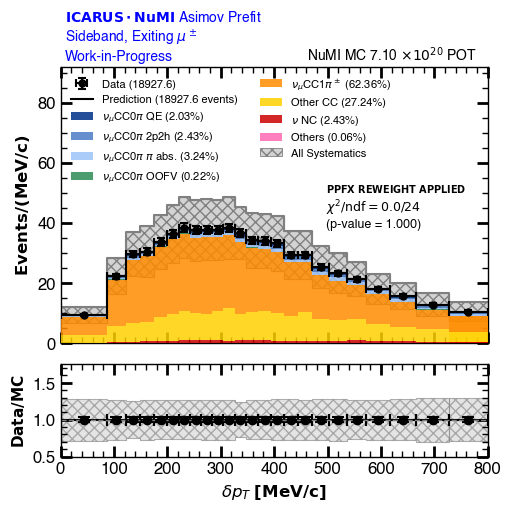

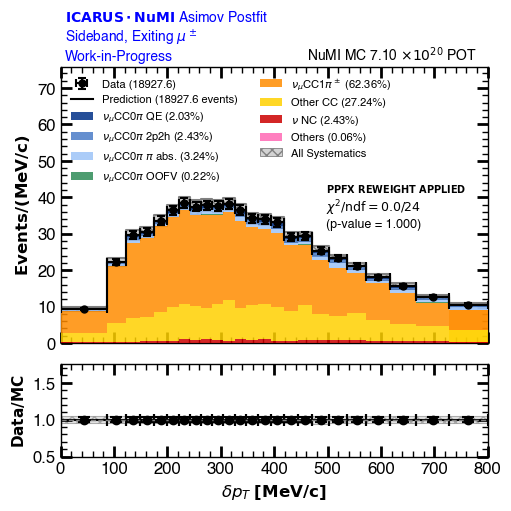

In [5]:
# Pre-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/Asimov_Containment/prefit_asimov_dpT_containment.root',
    fitterengine_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/Asimov_Containment/asimov_dpT_containment.root',
    sample_name='sideband_reco_dpT_exiting',
    variable_name='reco_dpT_lp',
    cov_bin_range=(57, 81),  # True block [57,82) includes the overflow row; sideband now uses its own binning (binning_reco_dpT_sideband_exiting.txt, 25 rows), not the selection's. Category histograms have 24 finite bins. See markdown note.
    fit_type='pre-fit',
    xlabel=r'$\delta p_T$ $\mathbf{[MeV/c]}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Asimov Prefit' + '\n' + 'Sideband, Exiting $\mu^\pm$' + '\n' + 'Work-in-Progress',
    save_dir=r'../Plots/dpT/Asimov_Containment/Prefits', save_name='prefit_dpT_sideband_exiting',
    pot=r'NuMI MC 7.10 $\times 10^{20}$ POT',
)

# Post-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/Asimov_Containment/postfit_asimov_dpT_containment.root',
    fitterengine_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/Asimov_Containment/asimov_dpT_containment.root',
    sample_name='sideband_reco_dpT_exiting',
    variable_name='reco_dpT_lp',
    cov_bin_range=(57, 81),  # see note above
    fit_type='post-fit',
    xlabel=r'$\delta p_T$ $\mathbf{[MeV/c]}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Asimov Postfit' + '\n' + 'Sideband, Exiting $\mu^\pm$' + '\n' + 'Work-in-Progress',
    pot=r'NuMI MC 7.10 $\times 10^{20}$ POT',
    save_dir=r'../Plots/dpT/Asimov_Containment/Postfits', save_name='postfit_dpT_sideband_exiting'
)

## Cross-Section Extraction

Extracted from `asimov_XSec_dpT_containment.root` (CalcXsec run on the containment-fit output). This is on the true-level `True_dpT_XS` sample and 7 truth bins -- unchanged by the reco-level containment split, so this section is structurally identical to the combined-fit version, just pointed at the containment fit's postfit parameters.

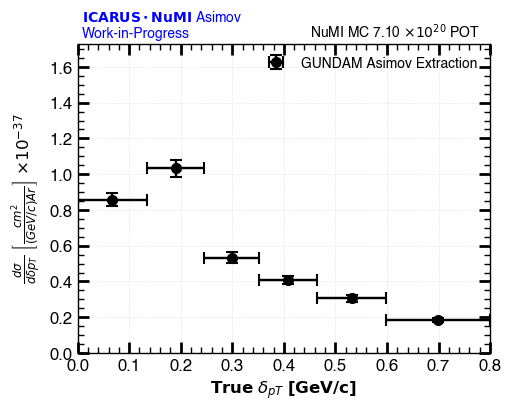

In [6]:
# Create the scatter plot and get the raw values
fig_xs, ax_xs, xsec_extracted_raw, xsec_extracted_errors_raw = plot_scatter(
    filename='/data/XSection/dpT/Asimov_Containment/asimov_XSec_dpT_containment_FluxBug.root',
    is_cross_section=True,
    hist_path="calcXsec/histograms/True_dpT_XS_TH1D;1",
    xlabel=r'$\mathbf{True}$ $\delta_{pT}$ $\mathbf{[GeV/c]}$',
    ylabel=r'$\frac{d\sigma}{d\delta p_T}$ $\left[\frac{cm^2}{(GeV/c)Ar}\right]$ $\times 10^{-37}$',
    bin_edges_labels=[0.0, 0.135, 0.246, 0.352, 0.465, 0.598, 0.8],
    is_y_errors=True,
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress',
    label="GUNDAM Asimov Extraction",
    pot=r'NuMI MC 7.10 $\times 10^{20}$ POT',
    scaling_power_of_10=1e40
)

save_fig(fig_xs, r'../Plots/dpT/Asimov_Containment/XSection', 'dpT_XS')


Signal Events and Cross-Section per True Bin
Bin Range (MeV/c)         N_Signal     Bin Width (MeV)    σ (x10^-37 cm²/GeV)
------------------------------------------------------------------------------------------
     0 - 135    MeV/c    30036        135                8.568524e-01
   135 - 246    MeV/c    29793        111                1.033721e+00
   246 - 352    MeV/c    14633        106                5.322510e-01
   352 - 465    MeV/c    12004        113                4.102019e-01
   465 - 598    MeV/c    10513        133                3.057068e-01
   598 - 800    MeV/c    9620         202                1.848052e-01
   800 - 99999  MeV/c    5870         ∞                  N/A (infinite bin)
------------------------------------------------------------------------------------------
Total                     112469


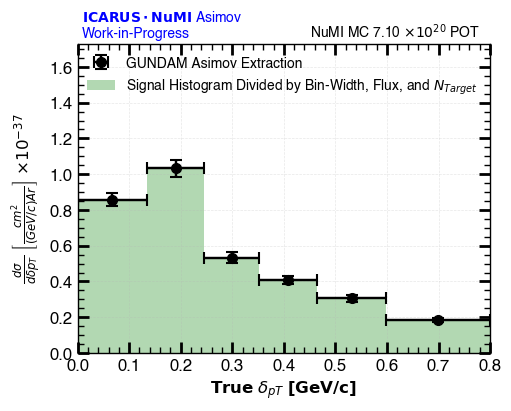

In [7]:
bins_mev = [(0, 135), (135, 246), (246, 352), (352, 465), (465, 598), (598, 800), (800, 99999)]
# Overlay manual calculation -- unaffected by the containment split (true-level signal tree, no containment cut)
fig, ax, xs = overlay_manual_cross_section(
    fig=fig_xs,
    ax=ax_xs,
    signal_tree_path="events/full/signal",
    root_file_path="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_Selection/data/icarus_numi_numu_mc_onbeam_offbeam_syst_gundam.root",
    bins_mev=bins_mev,
    n_targets=4.721444e30,
    flux=5.1915e11,
    color='green',
    marker='s',
    label=r'Signal Histogram Divided by Bin-Width, Flux, and $N_{Target}$',
    variable_name="true_dpT_lp_genie",
    scaling_power_of_10=1e37,
    energy_conversion=True
)
save_fig(fig, r'../Plots/dpT/Asimov_Containment/XSection', 'dpT_XS_wSignal')
display(fig)


GENIE NUISANCE Cross-Section (ICARUS_1muNp0pi_deltaPT)
Bin range                                 xsec
----------------------------------------------------------------------
  0.0000 – 0.1350           8.758637e-01
  0.1350 – 0.2460           1.059684e+00
  0.2460 – 0.3520           5.451330e-01
  0.3520 – 0.4650           4.246163e-01
  0.4650 – 0.5980           3.148177e-01
  0.5980 – 0.8000           1.866928e-01

χ² / Ndof = 1.4 / 6 = 0.234
p-value = 0.966


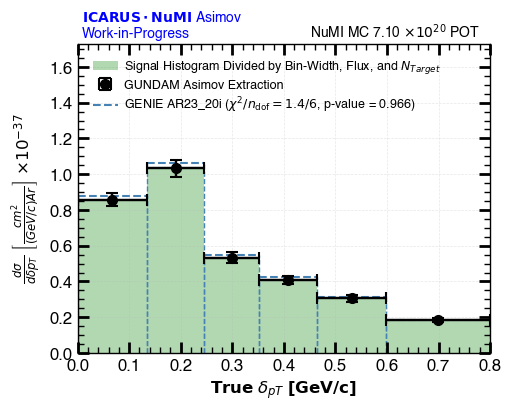

In [8]:
# Overlay GENIE with chi2
xsec_extracted = xsec_extracted_raw * 1e40
xsec_extracted_errors = xsec_extracted_errors_raw * 1e40

fig_genie, ax_genie, xsec_genie, chi2_info = overlay_genie_nuisance_xsec(
    fig_xs, ax_xs,
    nuisance_file_dir="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/GENIE/fhc_Nu14",
    nuisance_file_dir_numubar="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/GENIE/fhc_Nu-14",
    bin_edges=[0.0, 0.135, 0.246, 0.352, 0.465, 0.598, 0.80],
    nuisance_var='ICARUS_1muNp0pi_deltaPT',
    scaling_power_of_10=1e37,
    label='GENIE AR23_20i',
    extracted_xsec=xsec_extracted,
    extracted_xsec_errors=xsec_extracted_errors,
    add_ratio=False,
    draw_extracted_ratio=False,
)

save_fig(fig_genie, r'../Plots/dpT/Asimov_Containment/XSection', 'dpT_XS_wGENIE')
display(fig_genie)

## Template Parameter Post-fit Values

One set of 7 template parameters, shared across all four samples in the joint fit -- not split by containment.

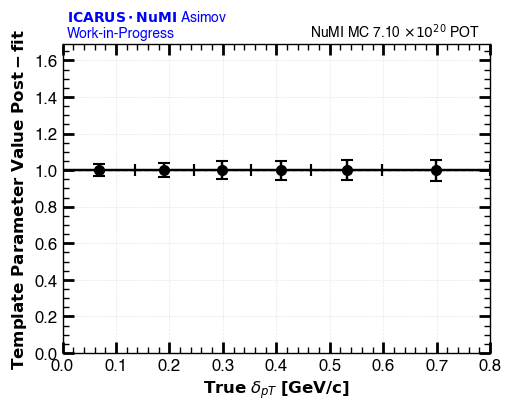

In [9]:
fig_template, ax_template, dummy, dummy2 = plot_scatter(
        filename='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/Asimov_Containment/asimov_dpT_containment.root',
        is_cross_section = False,
        hist_path="FitterEngine/postFit/Hesse/errors/Template Parameter true_dpT_lp_genie/values/postFitErrors_TH1D;1",
        xlabel=r'$\mathbf{True}$ $\delta_{pT}$ $\mathbf{[GeV/c]}$',
        ylabel='$\mathbf{Template\ Parameter\ Value\ Post-fit}$',
        bin_edges_labels=[0.0, 0.135, 0.246, 0.352, 0.465, 0.598, 0.8],
        is_y_errors = True,
        title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress',
        label=None,
        hline_nuisance=True,
        pot=r'NuMI MC 7.10 $\times 10^{20}$ POT'
)
save_fig(fig_template, r'../Plots/dpT/Asimov_Containment/TemplateParameters', 'dpT')

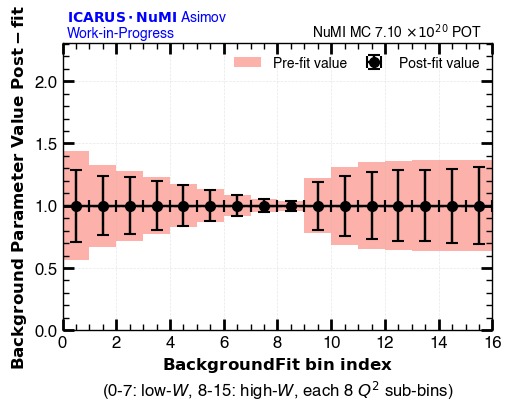

In [10]:
fig_bkg_template, ax_bkg_template, dummy, dummy2 = plot_scatter(
        filename='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/Asimov_Containment/asimov_dpT_containment.root',
        is_cross_section=False,
        hist_path="FitterEngine/postFit/Hesse/errors/BackgroundFit true_generator_w binbybin/values/postFitErrors_TH1D;1",
        xlabel=r'$\mathbf{BackgroundFit\ bin\ index}$' + '\n' + r'(0-7: low-$W$, 8-15: high-$W$, each 8 $Q^2$ sub-bins)',
        ylabel=r'$\mathbf{Background\ Parameter\ Value\ Post-fit}$',
        bin_edges_labels=list(range(17)),   # 17 edges -> 16 unit-width bins, matches the 16 real bins exactly
        remove_last_bin=False,               # there is no overflow bin in this scheme -- don't drop bin 15
        is_y_errors=True,
        title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress',
        hline_nuisance=True,
        pot=r'NuMI MC 7.10 $\times 10^{20}$ POT',
        show_prior=True,
)
save_fig(fig_bkg_template, r'../Plots/dpT/Asimov_Containment/BackgroundFitParameters', 'dpT')

## Nuisance Parameter Constraints

Pre-fit/post-fit constraint plots for the interaction-model, flux, and detector systematics. These dial sets are unaffected by the reco-level split (see the DetSys/GENIE parameterSet configs -- `applyOnDataSets` is keyed by dataset name, not fitSample name), so this is one set of plots for the whole joint fit.

Number of parameters: 52


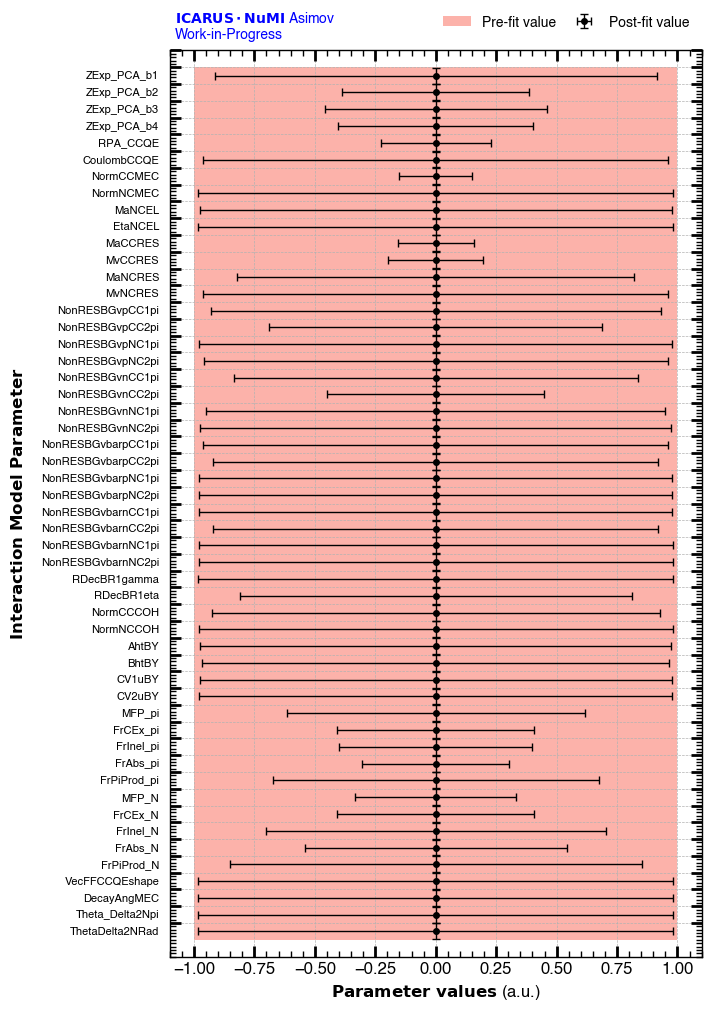

In [11]:
fig, ax = plot_fit_constraints(
    filename="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/Asimov_Containment/asimov_dpT_containment.root",
    figsize=(7, 10),
    y_label=r'$\mathbf{Interaction\ Model\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/Cross section Systematics/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/dpT/Asimov_Containment/NuisanceParameters', 'dpT_InteractionModel')

Number of parameters: 27


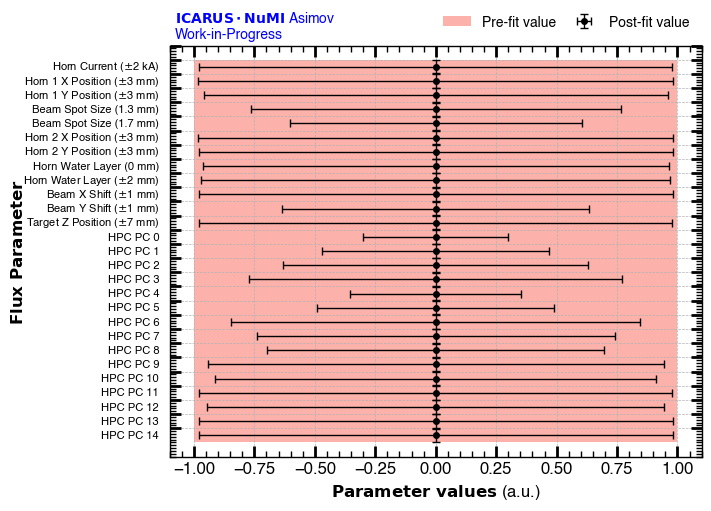

In [12]:
fig, ax = plot_fit_constraints(
    filename="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/Asimov_Containment/asimov_dpT_containment.root",
    figsize=(7, 5),
    y_label=r'$\mathbf{Flux\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/Multisigma Flux Systematics/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/dpT/Asimov_Containment/NuisanceParameters', 'dpT_Flux')

Number of parameters: 9


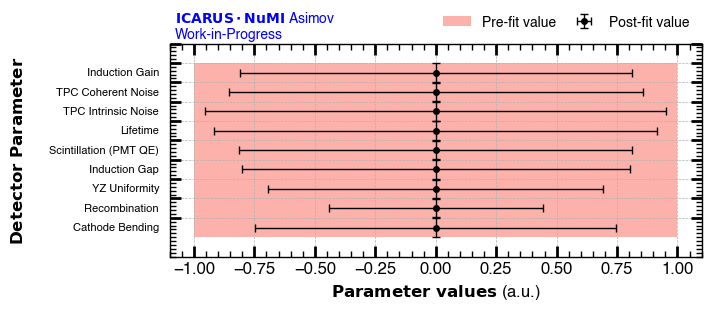

In [13]:
fig, ax = plot_fit_constraints(
    filename="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/Asimov_Containment/asimov_dpT_containment.root",
    figsize=(7, 3),
    y_label=r'$\mathbf{Detector\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/Detector Systematics/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/dpT/Asimov_Containment/NuisanceParameters', 'dpT_Detector')

In [14]:
fig, ax = plot_fit_constraints(
    filename="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/Asimov_Containment/asimov_dpT_containment.root",
    figsize=(7, 7),
    y_label=r'$\mathbf{G4\ Proton\ Fate\ (Contained)\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/G4 Proton Fate (contained)/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/dpT/Asimov_Containment/NuisanceParameters', 'dpT_G4_Proton_Contained')

KeyInFileError: not found: 'G4 Proton Fate (contained)' (with any cycle number)

    Available keys: 'G4 Proton Fate;1', 'G4 Proton Fate/matrices;1', 'G4 Proton Fate/values;1', 'G4 Proton Fate/valuesNorm;1', 'G4 Piminus Fate;1', 'G4 Piplus Fate;1', 'G4 Proton Fate/matrices/Covariance_TH2D;1', 'G4 Piminus Fate/matrices;1'...

in file /Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/Asimov_Containment/asimov_dpT_containment.root

Number of parameters: 11


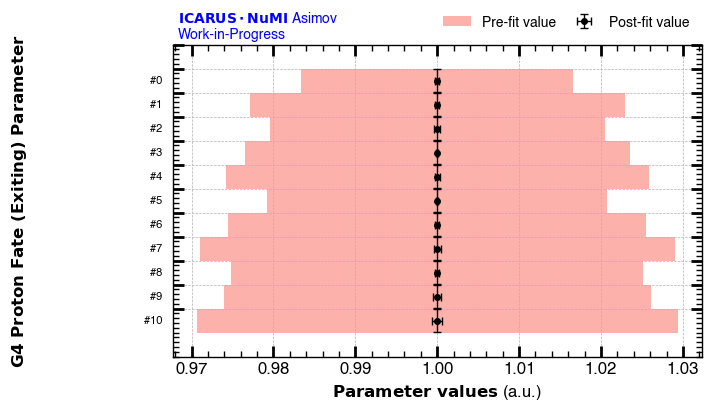

In [15]:
fig, ax = plot_fit_constraints(
    filename="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/Asimov_Containment/asimov_dpT_containment.root",
    figsize=(7, 4),
    y_label=r'$\mathbf{G4\ Proton\ Fate\ (Exiting)\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/G4 Proton Fate (exiting)/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/dpT/Asimov_Containment/NuisanceParameters', 'dpT_G4_Proton_Exiting')

Number of parameters: 21


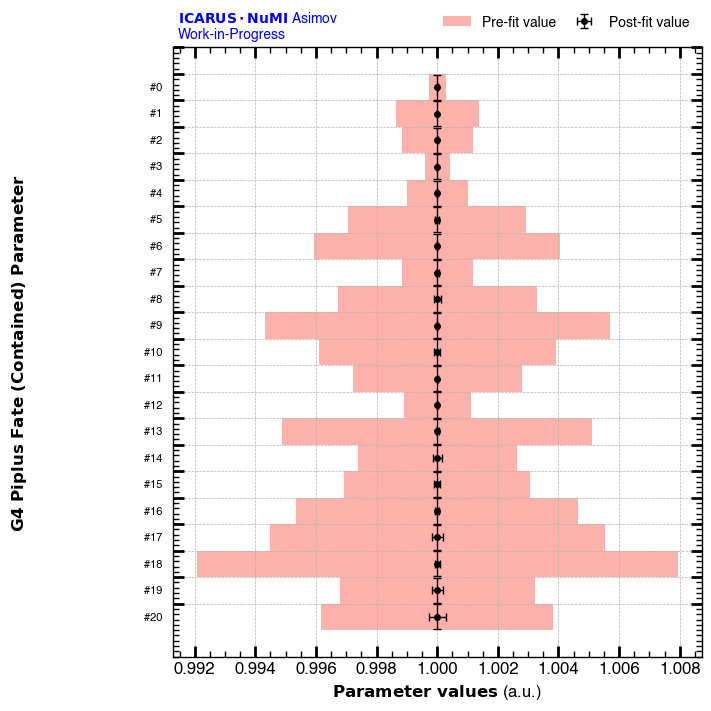

In [16]:
fig, ax = plot_fit_constraints(
    filename="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/Asimov_Containment/asimov_dpT_containment.root",
    figsize=(7, 7),
    y_label=r'$\mathbf{G4\ Piplus\ Fate\ (Contained)\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/G4 Piplus Fate (contained)/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/dpT/Asimov_Containment/NuisanceParameters', 'dpT_G4_Piplus_Contained')

Number of parameters: 11


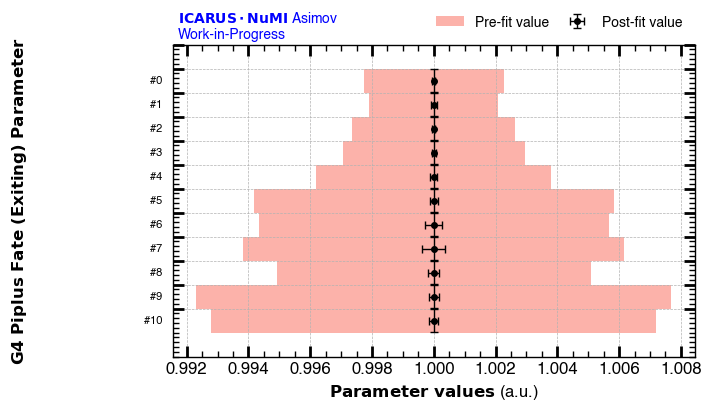

In [17]:
fig, ax = plot_fit_constraints(
    filename="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/Asimov_Containment/asimov_dpT_containment.root",
    figsize=(7, 4),
    y_label=r'$\mathbf{G4\ Piplus\ Fate\ (Exiting)\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/G4 Piplus Fate (exiting)/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/dpT/Asimov_Containment/NuisanceParameters', 'dpT_G4_Piplus_Exiting')

Number of parameters: 21


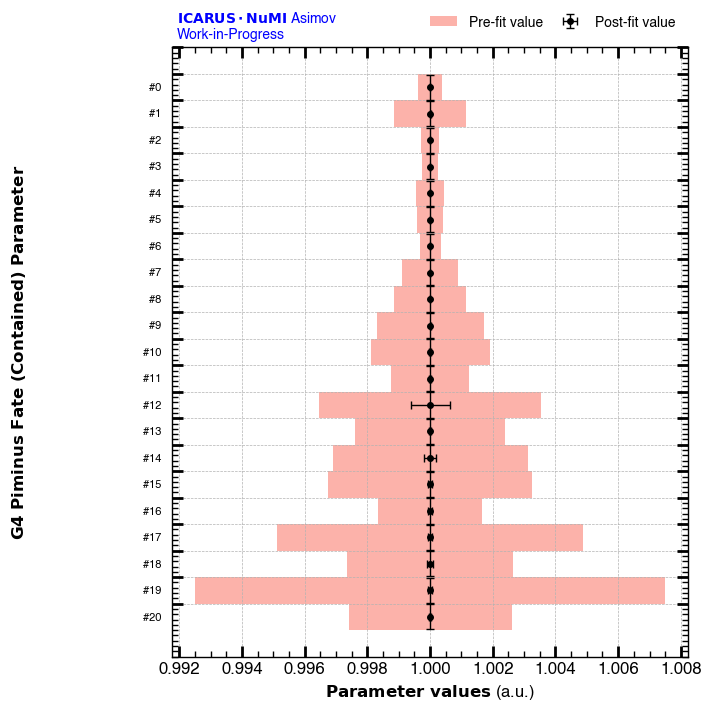

In [18]:
fig, ax = plot_fit_constraints(
    filename="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/Asimov_Containment/asimov_dpT_containment.root",
    figsize=(7, 7),
    y_label=r'$\mathbf{G4\ Piminus\ Fate\ (Contained)\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/G4 Piminus Fate (contained)/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/dpT/Asimov_Containment/NuisanceParameters', 'dpT_G4_Piminus_Contained')

Number of parameters: 11


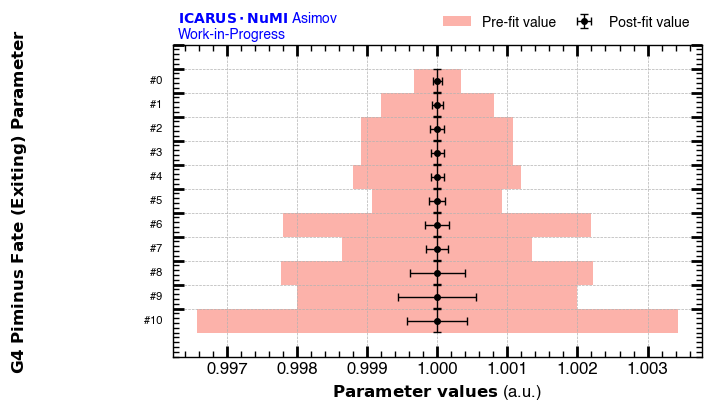

In [19]:
fig, ax = plot_fit_constraints(
    filename="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/Asimov_Containment/asimov_dpT_containment.root",
    figsize=(7, 4),
    y_label=r'$\mathbf{G4\ Piminus\ Fate\ (Exiting)\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/G4 Piminus Fate (exiting)/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/dpT/Asimov_Containment/NuisanceParameters', 'dpT_G4_Piminus_Exiting')

## Covariance / Correlation Matrices

Per-systematic-block matrices (interaction model, flux, detector) -- these are among the nuisance parameters themselves, not among reco bins, so `bin_range` is left at its default (full block) exactly as in the combined-fit notebook. Not to be confused with the reco-bin covariance used inside `plot_gundam_stacked`'s chi2 calculation, which is a different matrix (`toyGen/matrices/covarianceMatrix_TH2D`).

Full matrix size: 52×52


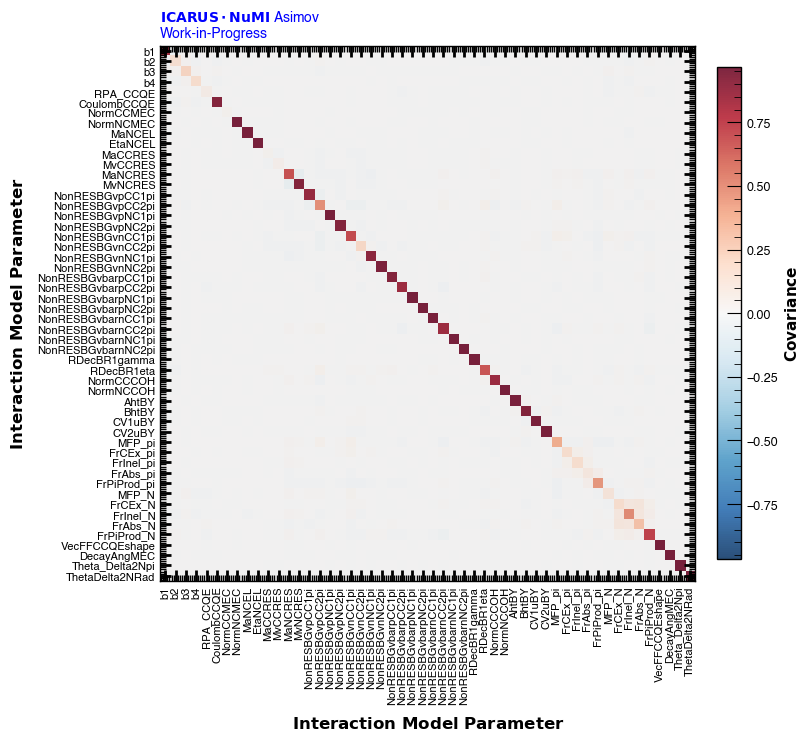

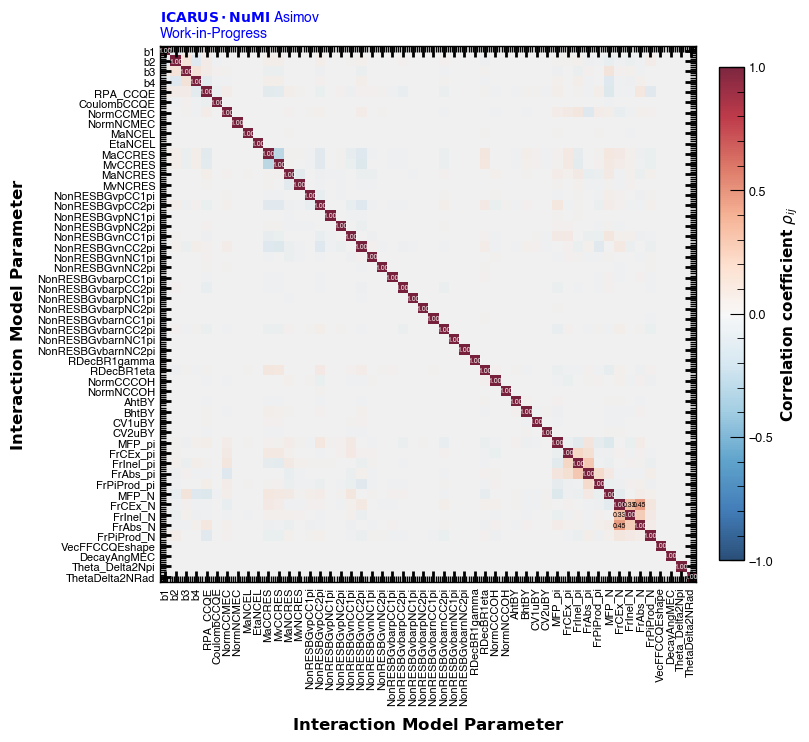

In [20]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/Asimov_Containment/asimov_dpT_containment.root',
    figsize=(8, 20),
    label_name=r"$\mathbf{Interaction\ Model\ Parameter}$",
    cov_path  = f"{BASE}/Cross section Systematics;1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/Cross section Systematics;1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'../Plots/dpT/Asimov_Containment/Postfits', 'xsec_param_covariance')
save_fig(fig_corr, r'../Plots/dpT/Asimov_Containment/Postfits', 'xsec_param_correlation')

Full matrix size: 27×27


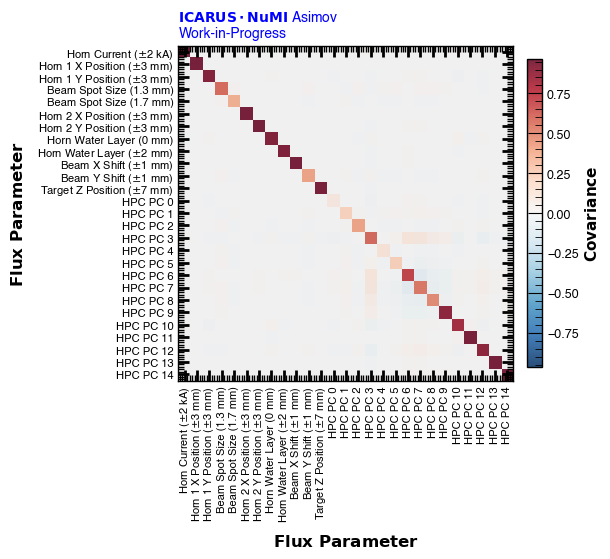

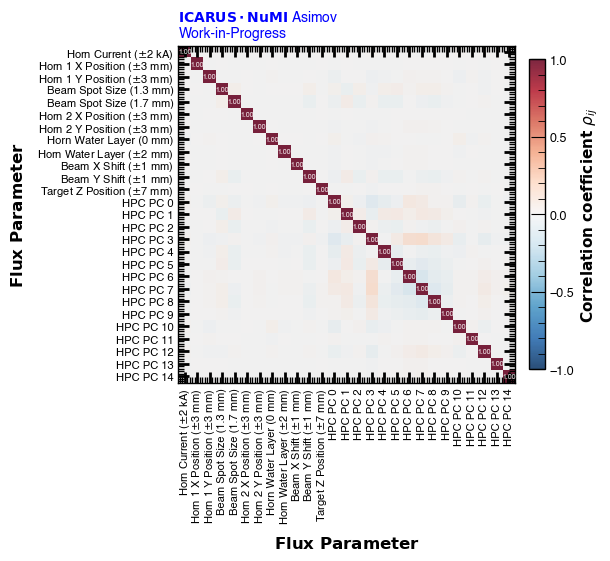

In [21]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/Asimov_Containment/asimov_dpT_containment.root',
    figsize=(6, 15),
    label_name=r"$\mathbf{Flux\ Parameter}$",
    cov_path  = f"{BASE}/Multisigma Flux Systematics;1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/Multisigma Flux Systematics;1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'../Plots/dpT/Asimov_Containment/Postfits', 'flux_param_covariance')
save_fig(fig_corr, r'../Plots/dpT/Asimov_Containment/Postfits', 'flux_param_correlation')

Full matrix size: 9×9


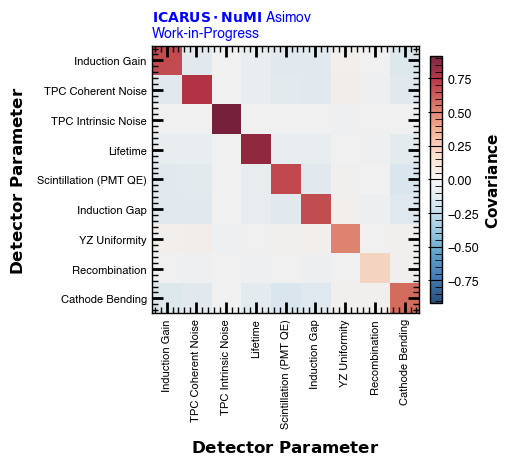

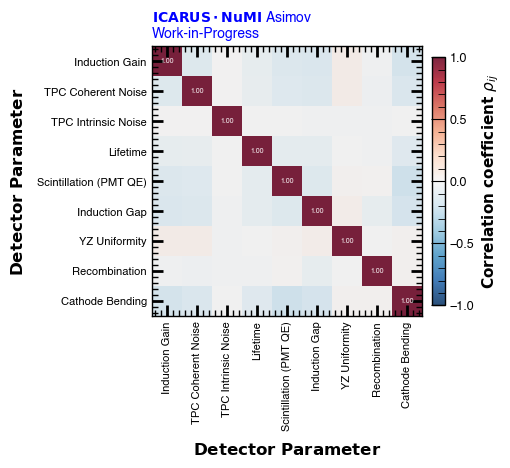

In [22]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/Asimov_Containment/asimov_dpT_containment.root',
    figsize=(5, 15),
    label_name=r"$\mathbf{Detector\ Parameter}$",
    cov_path  = f"{BASE}/Detector Systematics;1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/Detector Systematics;1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'../Plots/dpT/Asimov_Containment/Postfits', 'detector_param_covariance')
save_fig(fig_corr, r'../Plots/dpT/Asimov_Containment/Postfits', 'detector_param_correlation')

Full matrix size: 21×21


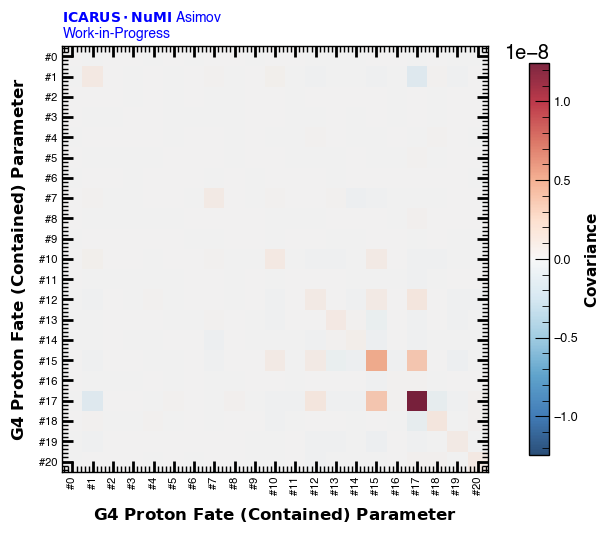

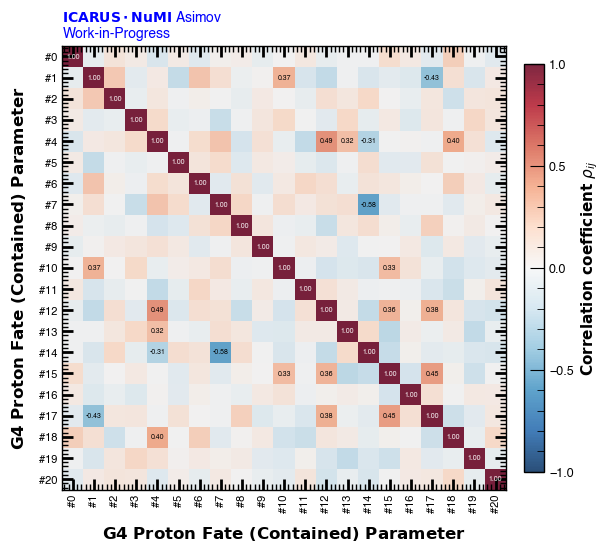

In [23]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/Asimov_Containment/asimov_dpT_containment.root',
    figsize=(6, 15),
    label_name=r"$\mathbf{G4\ Proton\ Fate\ (Contained)\ Parameter}$",
    cov_path  = f"{BASE}/G4 Proton Fate (contained);1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/G4 Proton Fate (contained);1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'../Plots/dpT/Asimov_Containment/Postfits', 'g4_proton_contained_param_covariance')
save_fig(fig_corr, r'../Plots/dpT/Asimov_Containment/Postfits', 'g4_proton_contained_param_correlation')

Full matrix size: 11×11


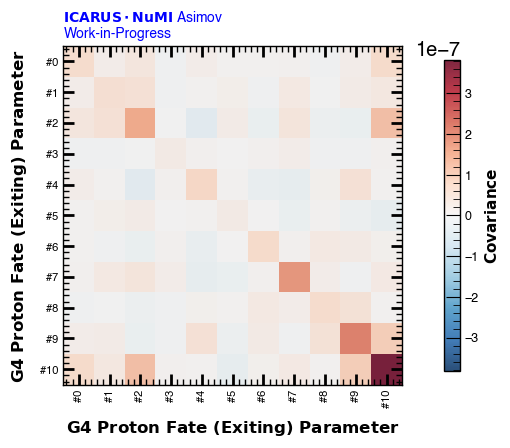

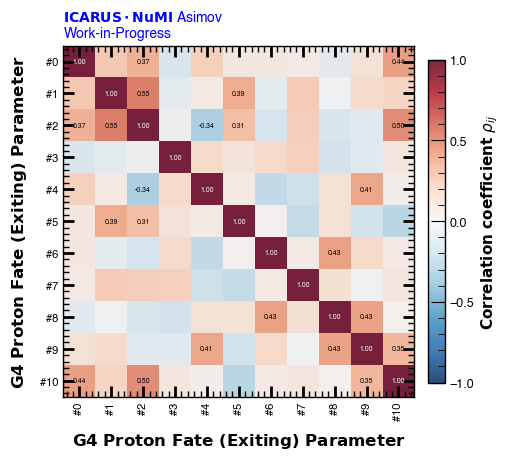

In [24]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/Asimov_Containment/asimov_dpT_containment.root',
    figsize=(5, 12),
    label_name=r"$\mathbf{G4\ Proton\ Fate\ (Exiting)\ Parameter}$",
    cov_path  = f"{BASE}/G4 Proton Fate (exiting);1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/G4 Proton Fate (exiting);1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'../Plots/dpT/Asimov_Containment/Postfits', 'g4_proton_exiting_param_covariance')
save_fig(fig_corr, r'../Plots/dpT/Asimov_Containment/Postfits', 'g4_proton_exiting_param_correlation')

Full matrix size: 21×21


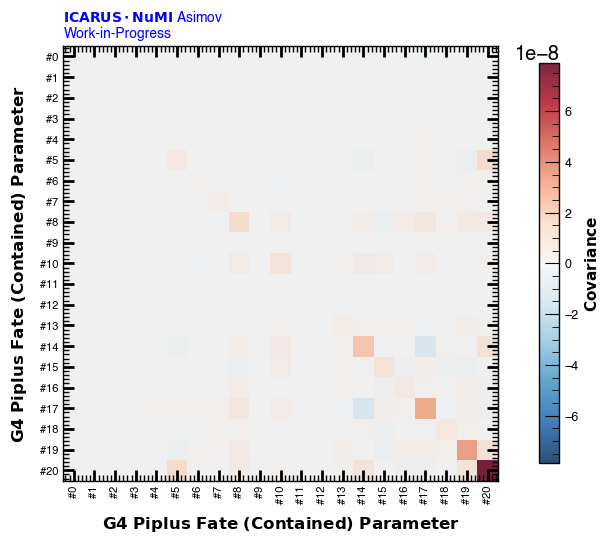

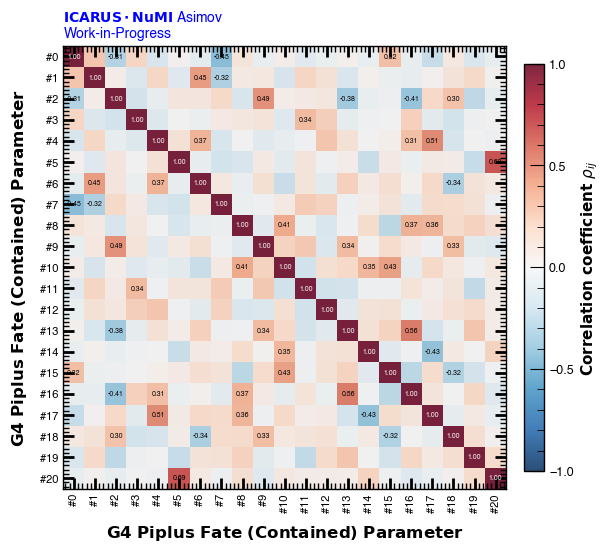

In [25]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/Asimov_Containment/asimov_dpT_containment.root',
    figsize=(6, 15),
    label_name=r"$\mathbf{G4\ Piplus\ Fate\ (Contained)\ Parameter}$",
    cov_path  = f"{BASE}/G4 Piplus Fate (contained);1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/G4 Piplus Fate (contained);1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'../Plots/dpT/Asimov_Containment/Postfits', 'g4_piplus_contained_param_covariance')
save_fig(fig_corr, r'../Plots/dpT/Asimov_Containment/Postfits', 'g4_piplus_contained_param_correlation')

Full matrix size: 11×11


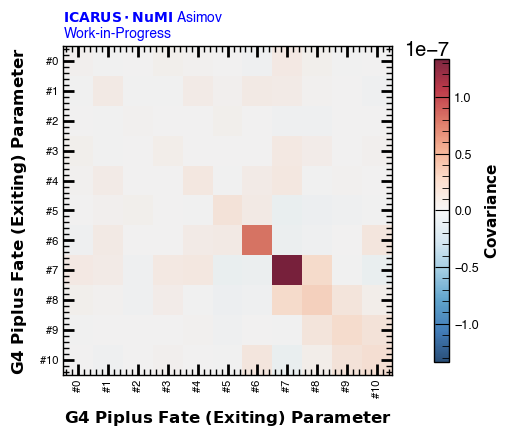

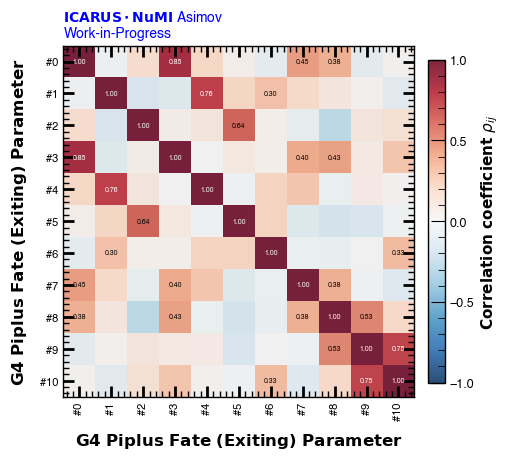

In [26]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/Asimov_Containment/asimov_dpT_containment.root',
    figsize=(5, 12),
    label_name=r"$\mathbf{G4\ Piplus\ Fate\ (Exiting)\ Parameter}$",
    cov_path  = f"{BASE}/G4 Piplus Fate (exiting);1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/G4 Piplus Fate (exiting);1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'../Plots/dpT/Asimov_Containment/Postfits', 'g4_piplus_exiting_param_covariance')
save_fig(fig_corr, r'../Plots/dpT/Asimov_Containment/Postfits', 'g4_piplus_exiting_param_correlation')

Full matrix size: 21×21


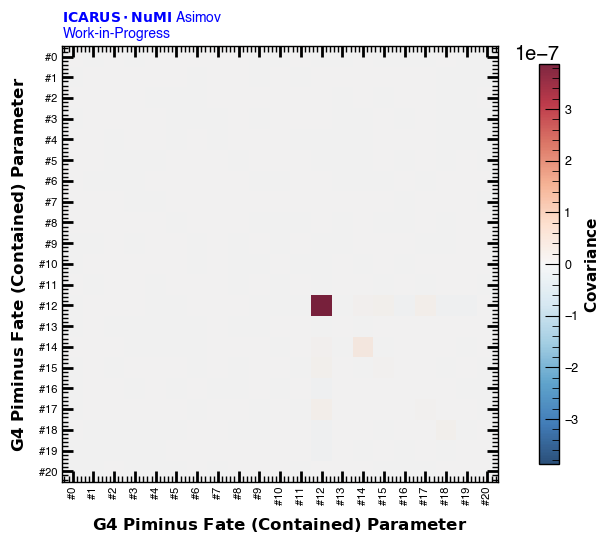

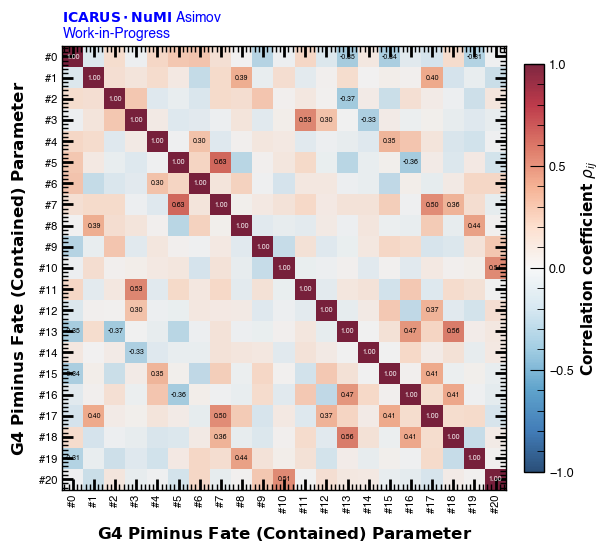

In [27]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/Asimov_Containment/asimov_dpT_containment.root',
    figsize=(6, 15),
    label_name=r"$\mathbf{G4\ Piminus\ Fate\ (Contained)\ Parameter}$",
    cov_path  = f"{BASE}/G4 Piminus Fate (contained);1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/G4 Piminus Fate (contained);1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'../Plots/dpT/Asimov_Containment/Postfits', 'g4_piminus_contained_param_covariance')
save_fig(fig_corr, r'../Plots/dpT/Asimov_Containment/Postfits', 'g4_piminus_contained_param_correlation')

Full matrix size: 11×11


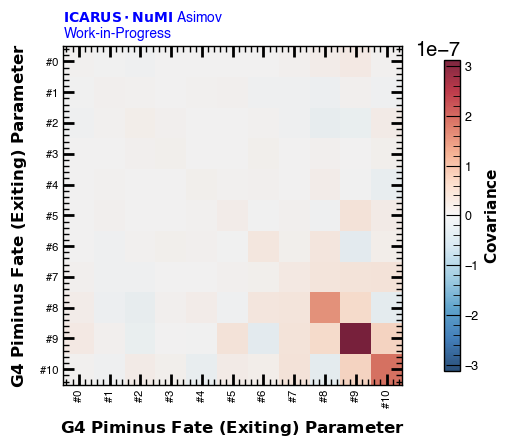

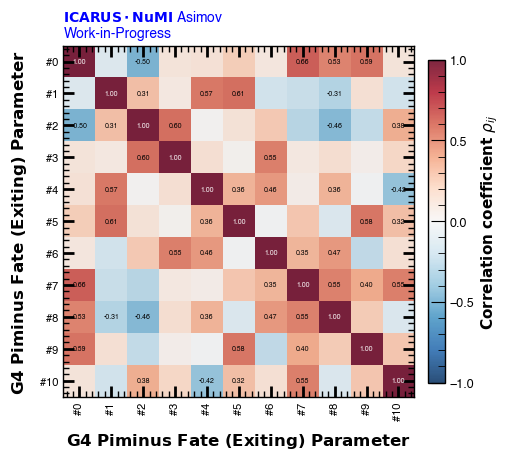

In [28]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/Asimov_Containment/asimov_dpT_containment.root',
    figsize=(5, 12),
    label_name=r"$\mathbf{G4\ Piminus\ Fate\ (Exiting)\ Parameter}$",
    cov_path  = f"{BASE}/G4 Piminus Fate (exiting);1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/G4 Piminus Fate (exiting);1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'../Plots/dpT/Asimov_Containment/Postfits', 'g4_piminus_exiting_param_covariance')
save_fig(fig_corr, r'../Plots/dpT/Asimov_Containment/Postfits', 'g4_piminus_exiting_param_correlation')

## Full Covariance / Correlation Matrix (All Systematics + Template Parameters)

Single matrix over every free parameter in the fit -- template, background-fit, cross-section, flux, detector, and all six G4 groups -- read from the fitter's own postfit Hessian block (`FitterEngine/postFit/Hesse/hessian`), not the per-group `errors` blocks the cells above use. `annotate` is left off here since the matrix is too large for per-cell values to be legible.

Full matrix size: 207×207


Locator attempting to generate 1035 ticks ([-0.4, ..., 206.4]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 1035 ticks ([-0.4, ..., 206.4]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 1035 ticks ([-0.4, ..., 206.4]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 1035 ticks ([-0.4, ..., 206.4]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 1035 ticks ([-0.4, ..., 206.4]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 1035 ticks ([-0.4, ..., 206.4]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 1035 ticks ([-0.4, ..., 206.4]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 1035 ticks ([-0.4, ..., 206.4]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 1035 ticks ([-0.4, ..., 206.4]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 1035 ticks ([-0.4, ..., 206.4]), which exc

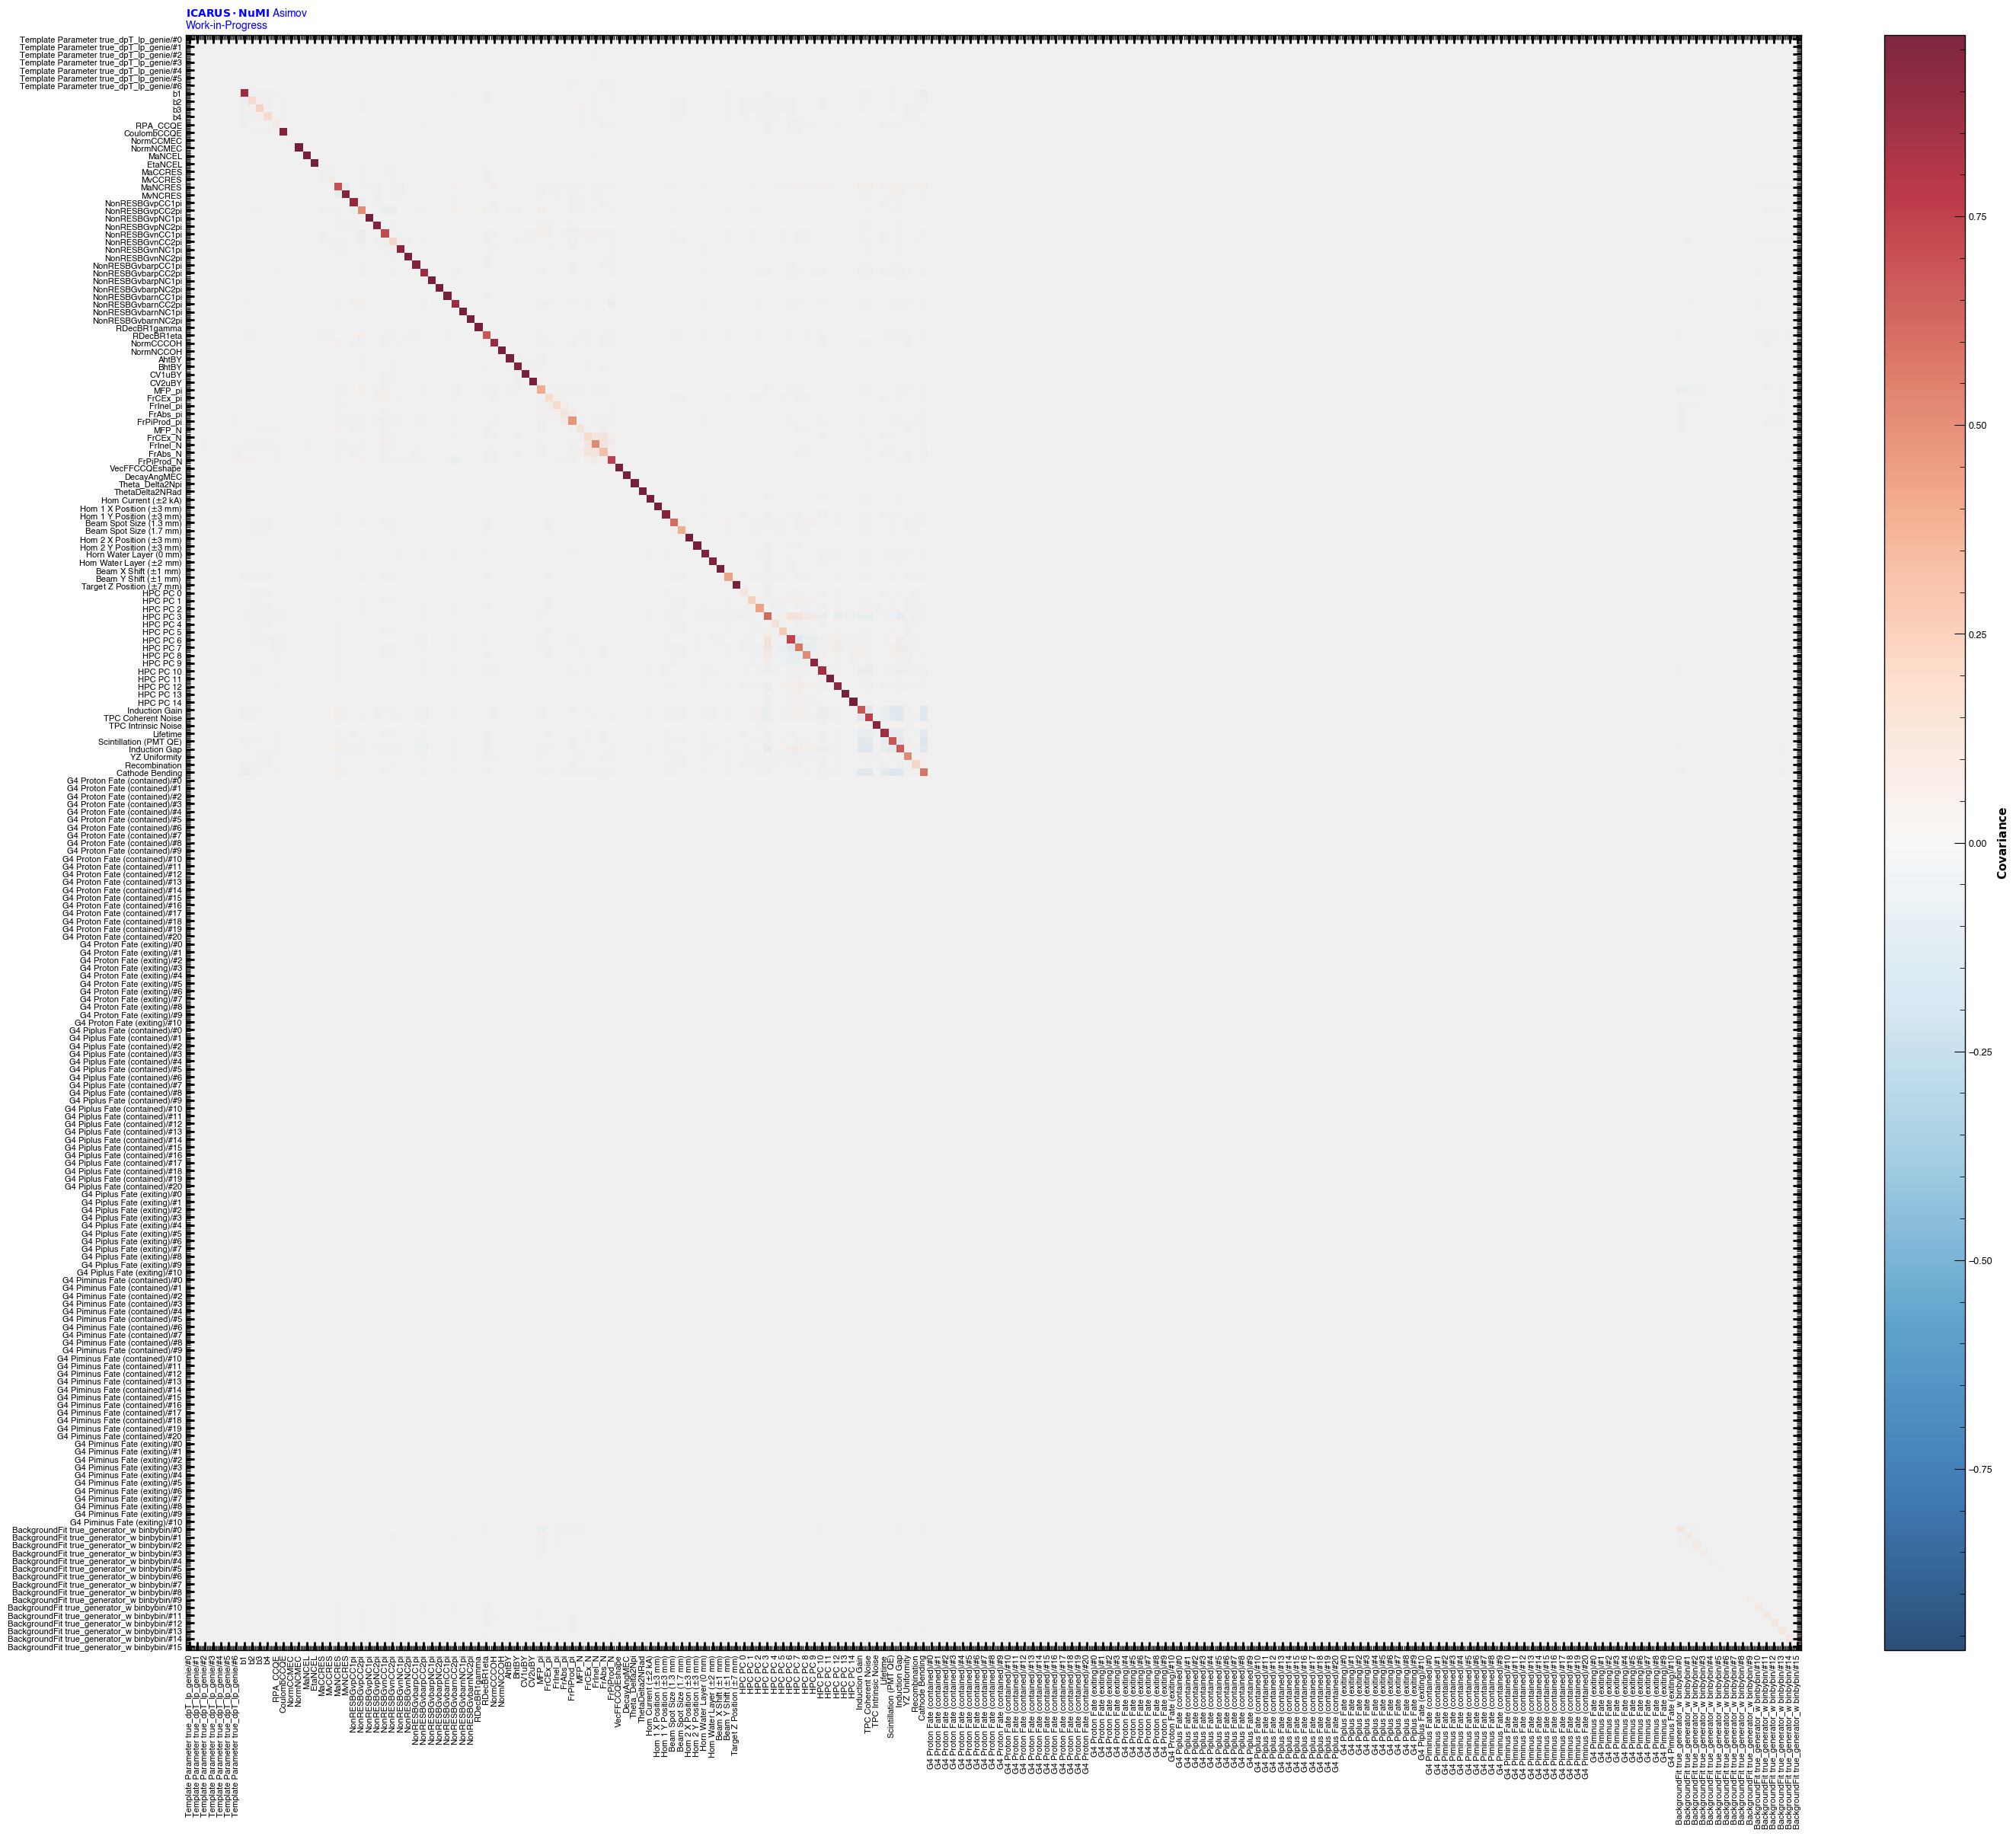

Locator attempting to generate 1035 ticks ([-0.4, ..., 206.4]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 1035 ticks ([-0.4, ..., 206.4]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 1035 ticks ([-0.4, ..., 206.4]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 1035 ticks ([-0.4, ..., 206.4]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 1035 ticks ([-0.4, ..., 206.4]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 1035 ticks ([-0.4, ..., 206.4]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 1035 ticks ([-0.4, ..., 206.4]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 1035 ticks ([-0.4, ..., 206.4]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 1035 ticks ([-0.4, ..., 206.4]), which exceeds Locator.MAXTICKS (1000).
Locator attempting to generate 1035 ticks ([-0.4, ..., 206.4]), which exc

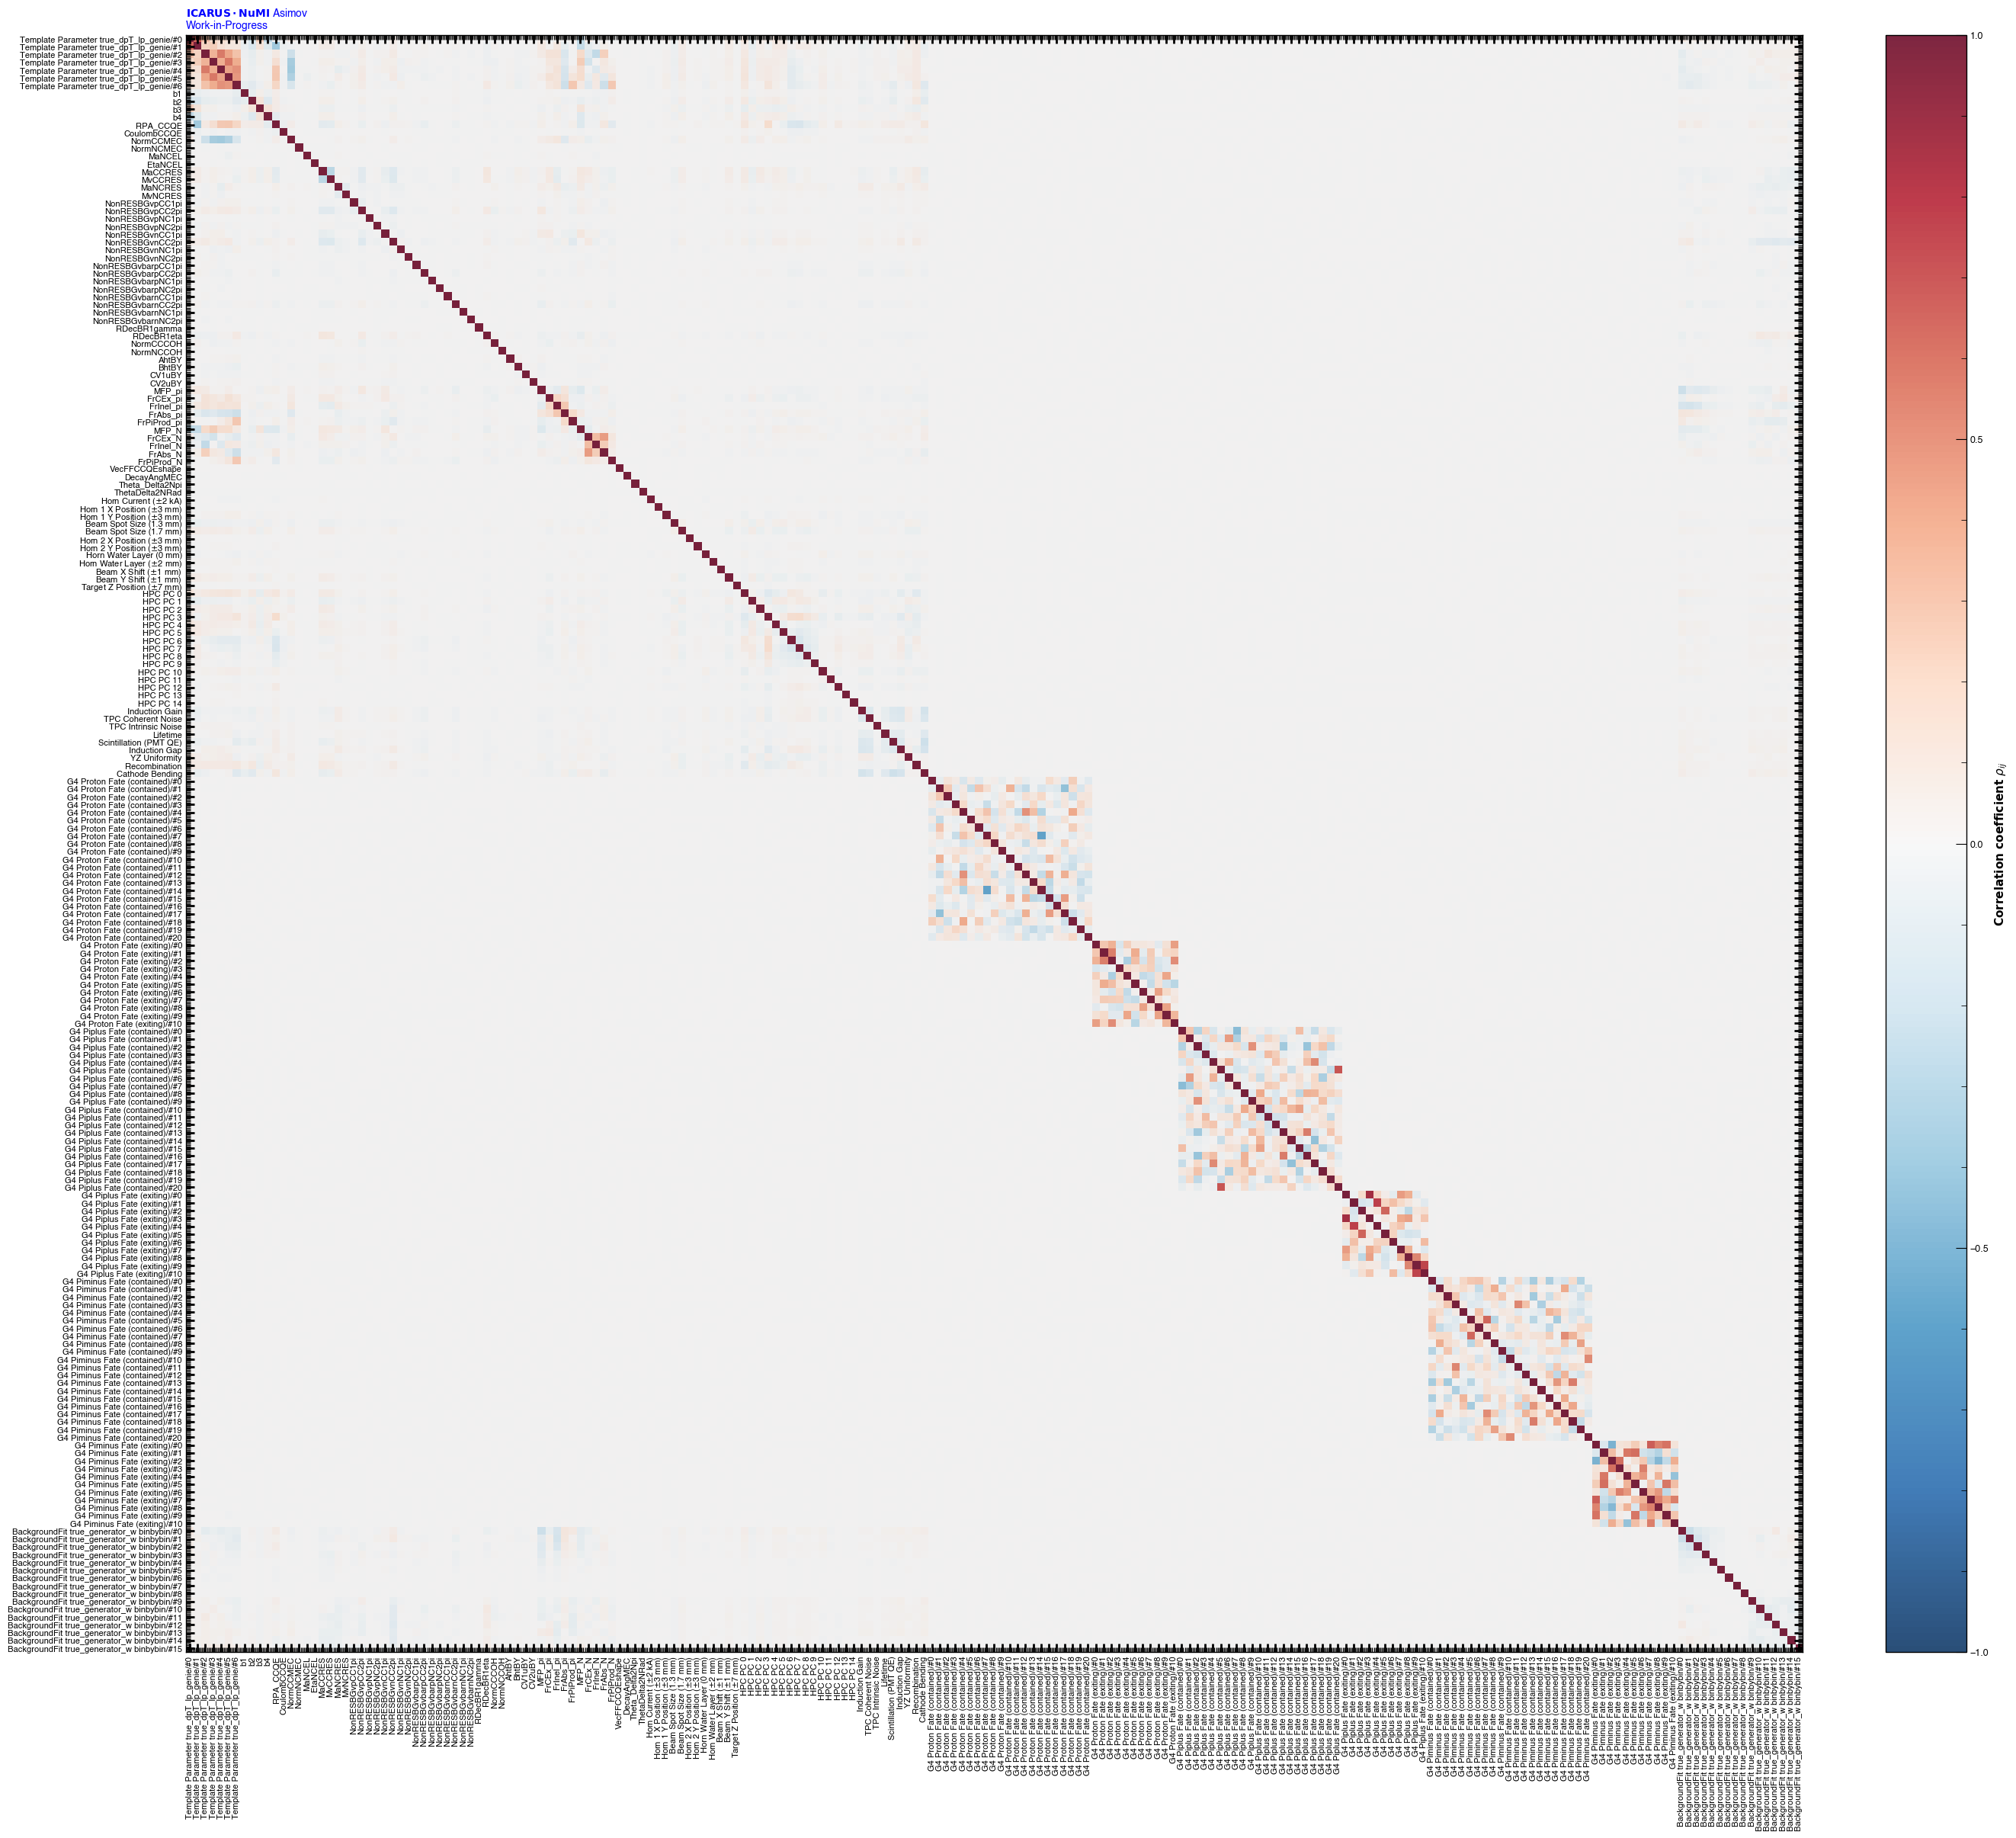

In [29]:
BASE_ALL = "FitterEngine/postFit/Hesse/hessian"
GROUP_ORDER = [
    "Template Parameter true_dpT_lp_genie",
    "Cross section Systematics",
    "Multisigma Flux Systematics",
    "Detector Systematics",
    "G4 Proton Fate (contained)",
    "G4 Proton Fate (exiting)",
    "G4 Piplus Fate (contained)",
    "G4 Piplus Fate (exiting)",
    "G4 Piminus Fate (contained)",
    "G4 Piminus Fate (exiting)",
    "BackgroundFit true_generator_w binbybin",
]
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/Asimov_Containment/asimov_dpT_containment.root',
    figsize=(30, 24),
    cov_path  = f"{BASE_ALL}/postfitCovariance_TH2D;1",
    corr_path = f"{BASE_ALL}/postfitCorrelation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress',
    annotate=False,
    group_order=GROUP_ORDER,
)
save_fig(fig_cov, r'../Plots/dpT/Asimov_Containment/Postfits', 'all_param_covariance')
save_fig(fig_corr, r'../Plots/dpT/Asimov_Containment/Postfits', 'all_param_correlation')



GENIE NUISANCE Cross-Section (ICARUS_1muNp0pi_deltaPT)
Bin range                                 xsec
----------------------------------------------------------------------
  0.0000 – 0.1350           2.809641e-01
  0.1350 – 0.2460           3.447836e-01
  0.2460 – 0.3520           1.600068e-01
  0.3520 – 0.4650           1.184918e-01
  0.4650 – 0.5980           8.469926e-02
  0.5980 – 0.8000           4.561175e-02

GENIE NUISANCE Cross-Section (ICARUS_1muNp0pi_deltaPT)
Bin range                                 xsec
----------------------------------------------------------------------
  0.0000 – 0.1350           6.046982e-01
  0.1350 – 0.2460           7.363447e-01
  0.2460 – 0.3520           3.731461e-01
  0.3520 – 0.4650           2.926601e-01
  0.4650 – 0.5980           2.192371e-01
  0.5980 – 0.8000           1.325582e-01

GENIE NUISANCE Cross-Section (ICARUS_1muNp0pi_deltaPT)
Bin range                                 xsec
---------------------------------------------------------

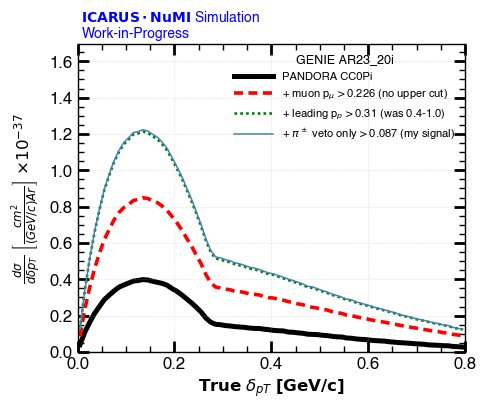

In [30]:
# GENIE cross section: signal definition morphing from Howard's to mine
import matplotlib.pyplot as plt
# Same axes/format as the other cross-section plots (plot_scatter), with the
# GUNDAM points removed so only the GENIE curves are shown.
fig_mor, ax_mor, _, _ = plot_scatter(
    filename='/data/XSection/dpT/Asimov_Containment/asimov_XSec_dpT_containment_FluxBug.root',
    is_cross_section=True,
    hist_path="calcXsec/histograms/True_dpT_XS_TH1D;1",
    xlabel=r'$\mathbf{True}$ $\delta_{pT}$ $\mathbf{[GeV/c]}$',
    ylabel=r'$\frac{d\sigma}{d\delta p_T}$ $\left[\frac{cm^2}{(GeV/c)Ar}\right]$ $\times 10^{-37}$',
    bin_edges_labels=[0.0, 0.135, 0.246, 0.352, 0.465, 0.598, 0.8],
    is_y_errors=True,
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Simulation' + '\n' + 'Work-in-Progress',
    label=None,
    pot='',
    scaling_power_of_10=1e40
)
# drop the GUNDAM extraction, keep the frame, ticks, title and labels
for art in list(ax_mor.lines) + list(ax_mor.collections):
    art.remove()
ax_mor.containers.clear()

steps = [
    ('ICARUS_1muNp0pi_IsSignal_Howard',        "PANDORA CC0Pi",                      'black'),
    ('ICARUS_1muNp0pi_IsSignal_muonChanged',   "+ muon p$_\\mu$ > 0.226 (no upper cut)", 'red'),
    ('ICARUS_1muNp0pi_IsSignal_protonChanged', "+ leading p$_p$ > 0.31 (was 0.4-1.0)",  'green'),
    ('ICARUS_1muNp0pi_IsSignal',               "+ $\\pi^\\pm$ veto only > 0.087 (my signal)", 'steelblue'),
]

# Line styles in draw order. Overlapping models stay distinguishable because the first is the
# thickest and solid, and each later one is thinner and drawn on top with a different dash pattern.
LINE_STYLES = [
    dict(linewidth=3.6, linestyle='-',             zorder=1),   # baseline: thick, solid, underneath
    dict(linewidth=2.6, linestyle=(0, (2.5, 1.5)), zorder=2),   # dashed
    dict(linewidth=1.9, linestyle=(0, (1.0, 1.2)), zorder=3),   # dotted
    dict(linewidth=1.1, linestyle='-',             zorder=4),   # thin solid on top
]

ymax = 0
for (branch, lab, col), sty in zip(steps, LINE_STYLES):
    _, _, xs, _ = overlay_genie_nuisance_xsec(
        fig_mor, ax_mor,
        nuisance_file_dir="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/GENIE/fhc_Nu14",
        nuisance_file_dir_numubar="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/GENIE/fhc_Nu-14",
        bin_edges=[0.0, 0.135, 0.246, 0.352, 0.465, 0.598, 0.80],
        nuisance_var='ICARUS_1muNp0pi_deltaPT',
        signal_expr=f'{branch} == True',
        scaling_power_of_10=1e37,
        label=lab, color=col,
        **sty,
        finer_binning=True,    # smooth curve on a fine grid instead of steps on the analysis bins
        n_fine_bins=80,       # 0 to 0.8 GeV/c in 0.01 GeV/c bins
        add_ratio=False,
    )
    ymax = max(ymax, float(max(xs)))

new_ymax = ymax * 1.6
ax_mor.set_ylim(0, new_ymax)

# plot_scatter placed the title/POT text above the *old* y-range; move them
# to just above the frame of the new one
for t in ax_mor.texts:
    t.set_position((t.get_position()[0], new_ymax + 0.01 * new_ymax))

# legend: steps in order, inside the frame (upper right, where the curves are low)
handles, labels = ax_mor.get_legend_handles_labels()
by_label = dict(zip(labels, handles))
order = [lab for _, lab, _ in steps]
ax_mor.legend([by_label[o] for o in order], order, loc='upper right',
              handlelength=3.5, fontsize=8, title='GENIE AR23_20i', title_fontsize=9, framealpha=0.8)

save_fig(fig_mor, r'../Plots/dpT/Asimov_Containment/XSection', 'dpT_XS_GENIE_signal_morphing')
plt.close(fig_mor)   # avoid the inline backend drawing the figure a second time
display(fig_mor)


## Post-fit Uncertainty Breakdown

Fractional uncertainty on the extracted cross section, split by source, following the N-X method (J. Kim):

- **Total**: all parameter sets free (the post-fit covariance of the template parameters, plus the flux-integral term below).
- **Stat.**: template parameters only, all nuisance parameters fixed.
- **Contribution of a group X**: $\sqrt{\sigma_{\rm All}^2 - \sigma_{{\rm All}-X}^2}$, where $\sigma_{{\rm All}-X}$ is the uncertainty with the parameters of X fixed. Here it is computed from the post-fit Hessian (rows and columns of X removed, then inverted) instead of a refit.
- **Cross-section (signal)**: the 20 QE, MEC and FSI GENIE dials; **Cross-section (bkgd.)**: the other 32 GENIE dials.
- **Flux**: flux parameters plus the flux-integral uncertainty (`Constant flux` `stdDev/meanValue`, read from the gundamCalcXsec config), added in quadrature.

The contributions do not add up to the total in quadrature because the post-fit parameters are correlated.


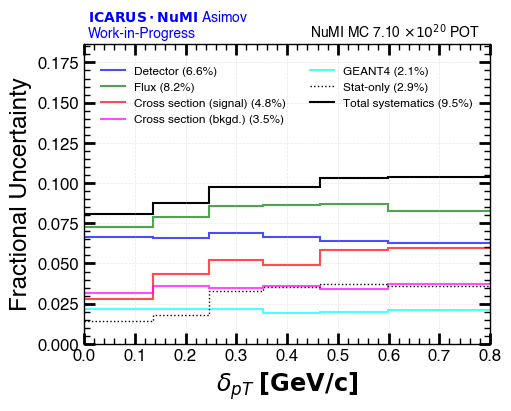

In [31]:
# N-X fractional uncertainty by source (Poisson, G4 KE2, gundamCalcXsec --TurnRecoOnlyOff)
# Same formatting as plot_postfit_uncertainty (previous cell).
import numpy as np, uproot
import matplotlib.pyplot as plt

plt.style.use('/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/style.mplstyle')

xs_dir = '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/XSection/dpT/Asimov_Containment/'
edges = np.array([0.0, 0.135, 0.246, 0.352, 0.465, 0.598, 0.8])   # GeV/c, finite truth bins
nb = len(edges) - 1

def rel_unc(fname):
    """sqrt(diag(cov)) / cross section from the gundamCalcXsec output (overflow bin dropped)."""
    f = uproot.open(xs_dir + fname)
    cov = f['calcXsec/matrices/covarianceMatrix_TH2D;1'].values()
    xs = f['calcXsec/histograms/True_dpT_XS_TH1D;1'].values()
    return (np.sqrt(np.diag(cov)) / xs)[:nb]

full = rel_unc('asimov_XSec_dpT_containment_G4KE2_recoOff_poisson.root')

def nx(tag):
    """Contribution of group X = sqrt(sigma_all^2 - sigma_noX^2)."""
    if tag == 'noG4':
        fn = 'asimov_XSec_dpT_containment_noG4_recoOff_poisson.root'
    else:
        fn = f'asimov_XSec_dpT_containment_{tag}_G4KE2_recoOff_poisson.root'
    return np.sqrt(np.clip(full**2 - rel_unc(fn)**2, 0, None))

# (values, legend label, color, linestyle, linewidth, alpha) -- same colors as plot_postfit_uncertainty
series = [
    (nx('noDet'),        'Detector',   'blue',    '-', 1.5, 0.7),
    (nx('noFlux'),       'Flux',                   'green',   '-', 1.5, 0.7),
    (nx('noXsecSignal'), 'Cross section (signal)', 'red',     '-', 1.5, 0.7),
    (nx('noXsecBkgd'),   'Cross section (bkgd.)',  'magenta', '-', 1.5, 0.7),
    (nx('noG4'),         'GEANT4',   'cyan',    '-', 1.5, 0.7),
    (rel_unc('asimov_XSec_dpT_containment_noSyst_poisson.root'), 'Stat-only', 'black', ':', 1.0, 1.0),
    (full,               'Total systematics',      'black',   '-', 1.5, 1.0),
]

fig_nx, ax_nx = plt.subplots(figsize=(5, 4))
ymax = 0.0
for vals, lab, col, ls, lw, al in series:
    ymax = max(ymax, vals.max())
    ax_nx.stairs(vals, edges, color=col, linestyle=ls, linewidth=lw, alpha=al,
                 label=f'{lab} ({np.mean(vals):.1%})', baseline=None)

ax_nx.set_xlim(edges[0], edges[-1])
ax_nx.set_ylim(0.0, 1.8 * ymax)
ax_nx.set_xlabel(r'$\delta_{pT}$ $\mathbf{[GeV/c]}$')
ax_nx.set_ylabel('Fractional Uncertainty', fontweight='bold')

ax_nx.tick_params(axis='both', which='major', labelsize=12, size=8, width=2, direction='in')
ax_nx.minorticks_on()
ax_nx.tick_params(axis='both', which='minor', size=4, width=1, direction='in')
for lt in ax_nx.get_xticklabels() + ax_nx.get_yticklabels():
    lt.set_fontfamily('sans-serif')
ax_nx.grid(True, alpha=0.3, linestyle='--')

yr, xr = ax_nx.get_ylim(), ax_nx.get_xlim()
usey = yr[1] + 0.01 * (yr[1] - yr[0])
usex = xr[0] + 0.01 * (xr[1] - xr[0])
ax_nx.text(x=usex, y=usey, s=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress',
           fontsize=10, color='blue', verticalalignment='bottom')
ax_nx.text(x=xr[1] - 0.025 * (xr[1] - xr[0]), y=usey, s=r'NuMI MC 7.10 $\times 10^{20}$ POT',
           fontsize=10, color='black', verticalalignment='bottom', horizontalalignment='right')
ax_nx.legend(loc='upper center', fontsize=8.5, ncol=2, borderaxespad=1.5)

save_fig(fig_nx, r'../Plots/dpT/Asimov_Containment/Uncertainties', 'dpT_nminusx_recoOff')
